5 dòng dữ liệu đầu tiên:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Độ chính xác: 100.0 %
Loài hoa dự đoán: setosa


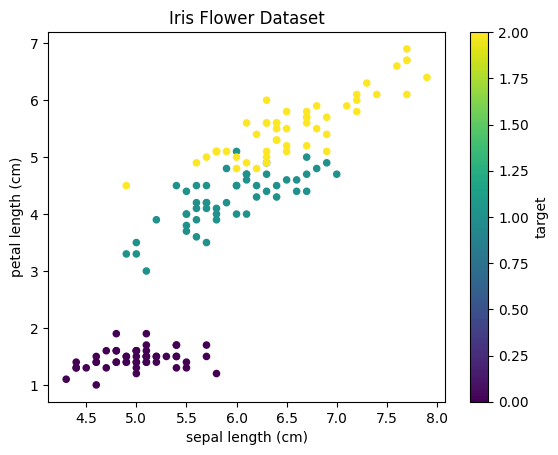

In [1]:
# 1. Import thư viện
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 2. Tải dữ liệu hoa Iris
iris = load_iris(as_frame=True)
df = iris.frame

print("5 dòng dữ liệu đầu tiên:")
print(df.head())

# 3. Chia dữ liệu để huấn luyện và kiểm tra
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Huấn luyện mô hình AI
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 5. Đánh giá kết quả
y_pred = model.predict(X_test)
print("\nĐộ chính xác:", accuracy_score(y_test, y_pred) * 100, "%")

# 6. Dự đoán một bông hoa mới
flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)
prediction = model.predict(flower)[0]

print("Loài hoa dự đoán:", iris.target_names[prediction])

# 7. Vẽ biểu đồ
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)
df.plot.scatter(
    x="sepal length (cm)",
    y="petal length (cm)",
    c="target",
    colormap="viridis"
)
plt.title("Iris Flower Dataset")
plt.show()

Đã tìm thấy: /kaggle/input/datasets/nguyenngoctrangquynh/tonghop/titanic/train.csv

5 dòng đầu tiên:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      

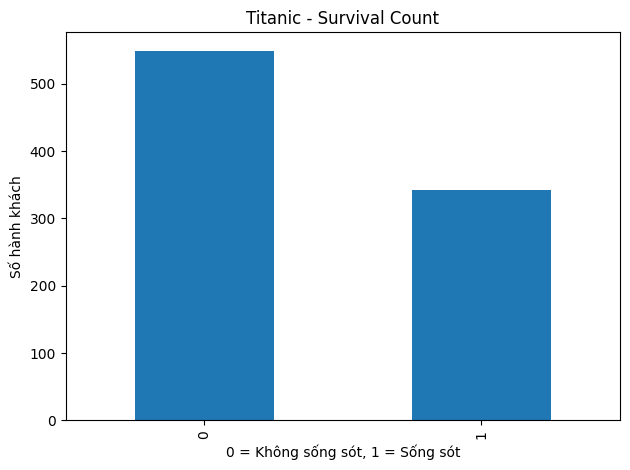

In [2]:
import os
import glob
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

# Tìm file train.csv trong dữ liệu Kaggle
files = glob.glob("/kaggle/input/**/train.csv", recursive=True)

if files:
    file_path = files[0]
    df = pd.read_csv(file_path)
    print("Đã tìm thấy:", file_path)

else:
    # Tìm file ZIP trong thư mục Input
    zip_files = glob.glob("/kaggle/input/**/*.zip", recursive=True)

    if zip_files:
        with zipfile.ZipFile(zip_files[0]) as z:
            csv_files = [
                f for f in z.namelist()
                if f.endswith("train.csv")
            ]

            if csv_files:
                with z.open(csv_files[0]) as f:
                    df = pd.read_csv(f)
                print("Đã đọc:", csv_files[0])
            else:
                raise FileNotFoundError(
                    "Không tìm thấy train.csv trong file ZIP."
                )
    else:
        raise FileNotFoundError(
            "Chưa tìm thấy dữ liệu Titanic trong Kaggle Input. "
            "Hãy nhấn Add Input để thêm dataset."
        )

# Hiển thị dữ liệu
print("\n5 dòng đầu tiên:")
print(df.head())

print("\nKích thước dữ liệu:", df.shape)

print("\nDữ liệu bị thiếu:")
print(df.isnull().sum())

print("\nSố hành khách sống sót:")
print(df["Survived"].value_counts())

print("\nTỷ lệ sống sót theo giới tính:")
print(df.groupby("Sex")["Survived"].mean())

df["Survived"].value_counts().plot(kind="bar")
plt.title("Titanic - Survival Count")
plt.xlabel("0 = Không sống sót, 1 = Sống sót")
plt.ylabel("Số hành khách")
plt.tight_layout()
plt.show()

Đã tìm thấy: /kaggle/input/datasets/nguyenngoctrangquynh/tonghop/netflix_titles.csv

5 dòng đầu tiên:
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-1

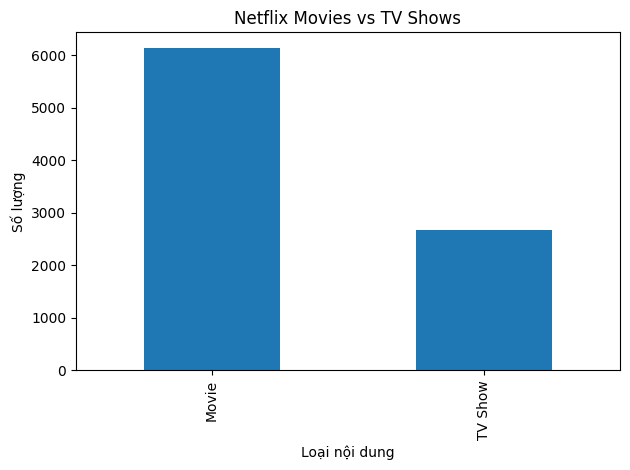

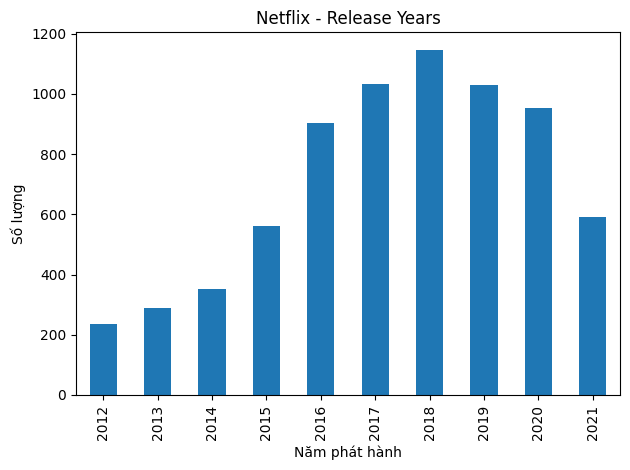

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Tìm file Netflix trong Kaggle Input
csv_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "netflix_titles.csv":
            csv_path = os.path.join(root, file)
            break
    if csv_path:
        break

if csv_path is None:
    print("Chưa tìm thấy file Netflix!")
    print("Hãy vào Add Input để thêm dataset Netflix.")
else:
    print("Đã tìm thấy:", csv_path)

    df = pd.read_csv(csv_path)

    print("\n5 dòng đầu tiên:")
    print(df.head())

    print("\nKích thước dữ liệu:", df.shape)

    print("\nSố dữ liệu bị thiếu:")
    print(df.isnull().sum())

    print("\nSố lượng phim và chương trình:")
    print(df["type"].value_counts())

    print("\n10 năm phát hành phổ biến:")
    print(df["release_year"].value_counts().head(10))

    # Biểu đồ 1
    df["type"].value_counts().plot(kind="bar")
    plt.title("Netflix Movies vs TV Shows")
    plt.xlabel("Loại nội dung")
    plt.ylabel("Số lượng")
    plt.tight_layout()
    plt.show()

    # Biểu đồ 2
    df["release_year"].value_counts().head(10).sort_index().plot(
        kind="bar"
    )
    plt.title("Netflix - Release Years")
    plt.xlabel("Năm phát hành")
    plt.ylabel("Số lượng")
    plt.tight_layout()
    plt.show()

CAC FILE CSV TIM DUOC:
/kaggle/input/datasets/nguyenngoctrangquynh/tonghop/netflix_titles.csv
/kaggle/input/datasets/nguyenngoctrangquynh/tonghop/Iris.csv
/kaggle/input/datasets/nguyenngoctrangquynh/tonghop/titanic/train.csv
/kaggle/input/datasets/nguyenngoctrangquynh/tonghop/titanic/test.csv
/kaggle/input/datasets/nguyenngoctrangquynh/tonghop/titanic/gender_submission.csv
Iris | Decision Tree | Accuracy: 0.9000 | F1: 0.8997
Iris | KNN | Accuracy: 0.9333 | F1: 0.9327
Iris | Random Forest | Accuracy: 0.9000 | F1: 0.8997
Titanic | Decision Tree | Accuracy: 0.8156 | F1: 0.8136
Titanic | KNN | Accuracy: 0.8156 | F1: 0.8128
Titanic | Random Forest | Accuracy: 0.8156 | F1: 0.8128
Netflix | Decision Tree | Accuracy: 0.9733 | F1: 0.9733
Netflix | KNN | Accuracy: 0.9415 | F1: 0.9409
Netflix | Random Forest | Accuracy: 0.9728 | F1: 0.9725

===== BANG KET QUA 9 THUC NGHIEM =====
Dataset    Thuat toan  Accuracy  Precision  Recall  F1-score
   Iris Decision Tree    0.9000     0.9024  0.9000    0.89

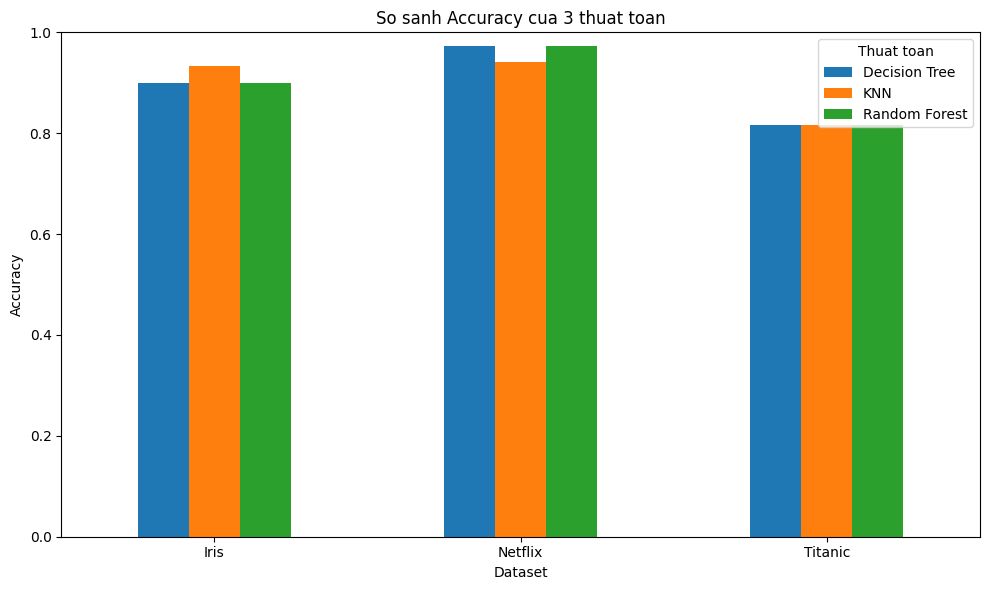


Da luu bang ket qua vao:
/kaggle/working/ket_qua_9_thuc_nghiem.csv


In [4]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# =====================================
# 1. TIM CAC FILE DATASET
# =====================================
all_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith(".csv"):
            all_files.append(os.path.join(root, file))

def find_file(filename):
    matches = [
        f for f in all_files
        if os.path.basename(f).lower() == filename.lower()
    ]
    return matches[0] if matches else None

iris_path = find_file("Iris.csv")
titanic_path = find_file("train.csv")
netflix_path = find_file("netflix_titles.csv")

# Hien thi cac file tim thay
print("CAC FILE CSV TIM DUOC:")
for f in all_files:
    print(f)

# =====================================
# 2. KHAI BAO 3 THUAT TOAN
# =====================================
algorithms = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

# =====================================
# 3. HAM THUC NGHIEM
# =====================================
def experiment(dataset_name, df, target, features):
    global results

    data = df[features + [target]].copy()
    data = data.dropna(subset=[target])

    X = data[features]
    y = data[target]

    # Loai bo cot khong co gia tri phan biet
    X = X.loc[:, X.nunique(dropna=False) > 1]

    if y.nunique() < 2:
        print("Bo qua", dataset_name,
              "- can it nhat 2 lop du lieu")
        return

    numeric_cols = X.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_cols = [
        c for c in X.columns
        if c not in numeric_cols
    ]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ])

    preprocess = ColumnTransformer([
        ("num", numeric_pipe, numeric_cols),
        ("cat", categorical_pipe, categorical_cols)
    ])

    # Chia tap huan luyen va kiem tra
    stratify = y if y.value_counts().min() >= 2 else None

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=stratify
    )

    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocess", preprocess),
            ("model", algorithm)
        ])

        model.fit(X_train, y_train)
        prediction = model.predict(X_test)

        result = {
            "Dataset": dataset_name,
            "Thuat toan": name,
            "Accuracy": accuracy_score(
                y_test, prediction
            ),
            "Precision": precision_score(
                y_test, prediction,
                average="weighted",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test, prediction,
                average="weighted",
                zero_division=0
            ),
            "F1-score": f1_score(
                y_test, prediction,
                average="weighted",
                zero_division=0
            )
        }

        results.append(result)

        print(
            f"{dataset_name} | {name} | "
            f"Accuracy: {result['Accuracy']:.4f} | "
            f"F1: {result['F1-score']:.4f}"
        )

# =====================================
# 4. DATASET IRIS
# =====================================
if iris_path:
    iris_df = pd.read_csv(iris_path)

    # Tim cot nhan loai hoa
    target = next(
        (c for c in iris_df.columns
         if c.lower() == "species"),
        None
    )

    if target is None:
        print("Khong tim thay cot Species trong Iris")
    else:
        features = [
            c for c in iris_df.columns
            if c != target
            and c.lower() not in ["id"]
            and pd.api.types.is_numeric_dtype(iris_df[c])
        ]

        experiment(
            "Iris", iris_df, target, features
        )
else:
    print("Khong tim thay Iris.csv")

# =====================================
# 5. DATASET TITANIC
# =====================================
if titanic_path:
    titanic_df = pd.read_csv(titanic_path)

    target = "Survived"

    features = [
        c for c in [
            "Pclass", "Sex", "Age", "SibSp",
            "Parch", "Fare", "Embarked"
        ]
        if c in titanic_df.columns
    ]

    if target in titanic_df.columns and features:
        experiment(
            "Titanic", titanic_df, target, features
        )
    else:
        print("Titanic khong co cot Survived hoac features")
else:
    print("Khong tim thay train.csv cua Titanic")

# =====================================
# 6. DATASET NETFLIX
# =====================================
if netflix_path:
    netflix_df = pd.read_csv(netflix_path)

    target = "type"

    features = [
        c for c in [
            "release_year", "rating",
            "country", "listed_in"
        ]
        if c in netflix_df.columns
    ]

    if target in netflix_df.columns and features:
        experiment(
            "Netflix", netflix_df, target, features
        )
    else:
        print("Netflix thieu cot type hoac features")
else:
    print("Khong tim thay netflix_titles.csv")

# =====================================
# 7. TONG HOP KET QUA 9 THUC NGHIEM
# =====================================
if results:
    result_df = pd.DataFrame(results)

    print("\n===== BANG KET QUA 9 THUC NGHIEM =====")
    print(
        result_df.round(4).to_string(index=False)
    )

    # Luu bang ket qua de lam bao cao
    result_df.to_csv(
        "/kaggle/working/ket_qua_9_thuc_nghiem.csv",
        index=False
    )

    # Bieu do so sanh Accuracy
    pivot = result_df.pivot(
        index="Dataset",
        columns="Thuat toan",
        values="Accuracy"
    )

    pivot.plot(kind="bar", figsize=(10, 6))
    plt.title("So sanh Accuracy cua 3 thuat toan")
    plt.xlabel("Dataset")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    print("\nDa luu bang ket qua vao:")
    print("/kaggle/working/ket_qua_9_thuc_nghiem.csv")


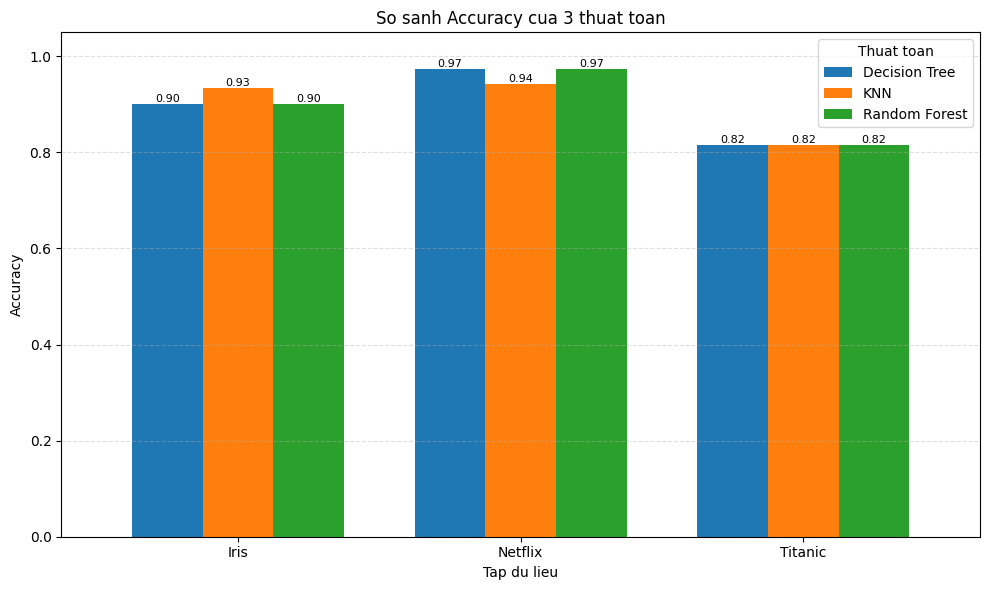

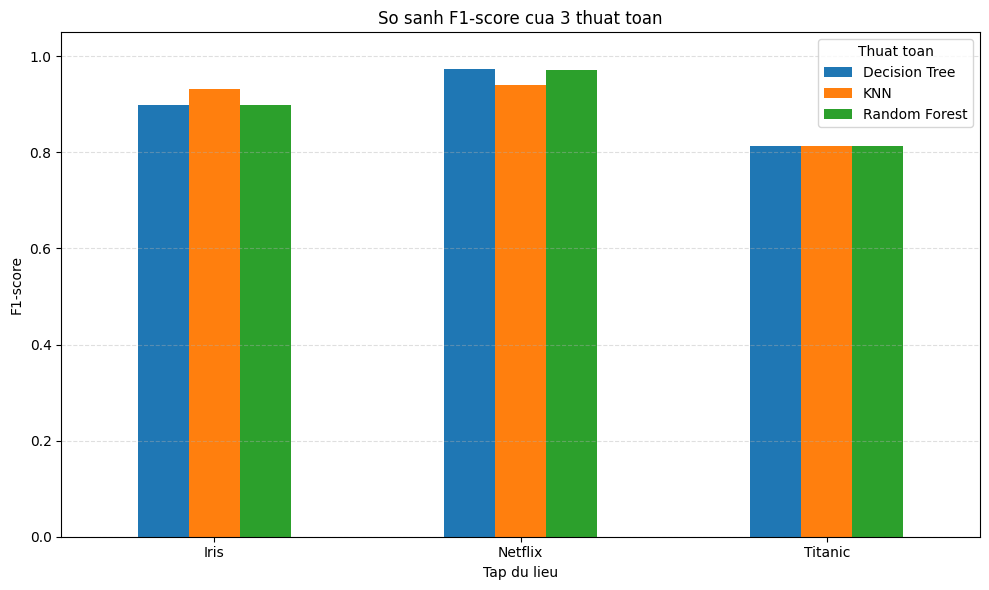

In [5]:

import matplotlib.pyplot as plt
import numpy as np

# 1. Bieu do so sanh Accuracy
pivot = result_df.pivot(
    index="Dataset",
    columns="Thuat toan",
    values="Accuracy"
)

ax = pivot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("So sanh Accuracy cua 3 thuat toan")
plt.xlabel("Tap du lieu")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Thuat toan")
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Hien thi gia tri tren cot
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)

plt.tight_layout()
plt.show()

# 2. Bieu do so sanh F1-score
pivot_f1 = result_df.pivot(
    index="Dataset",
    columns="Thuat toan",
    values="F1-score"
)

pivot_f1.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("So sanh F1-score cua 3 thuat toan")
plt.xlabel("Tap du lieu")
plt.ylabel("F1-score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [6]:

# Tim thuat toan co Accuracy cao nhat tren tung dataset
best_results = result_df.loc[
    result_df.groupby("Dataset")["Accuracy"].idxmax()
]

print("THUAT TOAN CO ACCURACY CAO NHAT:")
print(
    best_results[
        ["Dataset", "Thuat toan", "Accuracy", "F1-score"]
    ].round(4).to_string(index=False)
)


THUAT TOAN CO ACCURACY CAO NHAT:
Dataset    Thuat toan  Accuracy  F1-score
   Iris           KNN    0.9333    0.9327
Netflix Decision Tree    0.9733    0.9733
Titanic Decision Tree    0.8156    0.8136
